# PPO on LunarLander-v3

A Proximal Policy Optimization (PPO) agent learns to land the lunar module on its own, by trial and error.
The environment is considered solved when the agent reaches a mean score of at least 200 over 100 consecutive episodes, played without exploration.

The notebook reads from top to bottom and must run with *Restart & Run All*.

1. Setup
2. Environment
3. Random baseline
4. Actor and critic
5. Rollout storage and advantages
6. PPO update
7. Training
8. Results
9. Experiments
10. Comparison with DQN
11. Conclusion

## 1. Setup

In [58]:
import random
from collections import Counter
from dataclasses import dataclass, replace
from typing import Protocol

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.distributions import Categorical


### Reproducibility

Several libraries draw random numbers in this notebook, and each one has its own generator:

| Library | Used for |
|---|---|
| `random` | the random baseline agent |
| `numpy` | shuffling and statistics helpers |
| `torch` | the initial weights of the networks and the sampling of actions from the policy |

Seeding only one of them would leave the others unpredictable, so `set_seed` fixes the three at once.
It is a function rather than three lines at the top of the notebook because section 8 trains the agent with several seeds: the generators must be reset before each run.

The environment has a generator of its own. It is seeded separately in section 2, through `env.reset(seed=...)`.

In [59]:
def set_seed(*, seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


SEED = 42
set_seed(seed=SEED)

## 2. Environment

LunarLander-v3 is a 2D landing task simulated with Box2D physics. Gymnasium takes care of the physics, the rewards and the rendering, so this notebook only deals with the agent.

The environment is created without a `render_mode`. Drawing every frame would slow training down a lot, and the agent does not need images: it only reads the observation vector. The display window is opened by `model.py` only, to watch a trained agent.

### Observations

At each step, the agent receives a vector of 8 values:

| Index | Name | Description |
|---|---|---|
| 0 | `x` | horizontal position (the landing pad is at 0, the screen edges at ±1) |
| 1 | `y` | vertical position |
| 2 | `v_x` | horizontal velocity |
| 3 | `v_y` | vertical velocity |
| 4 | `theta` | angle of the lander |
| 5 | `theta_dot` | angular velocity |
| 6 | `left_leg_contact` | 1 if the left leg touches the ground, 0 otherwise |
| 7 | `right_leg_contact` | 1 if the right leg touches the ground, 0 otherwise |

### Actions

The agent picks one of 4 discrete actions:

| Action | Effect |
|---|---|
| 0 | do nothing |
| 1 | fire the left orientation engine |
| 2 | fire the main engine |
| 3 | fire the right orientation engine |

### End of an episode

| Flag | Cause | Is there a future? |
|---|---|---|
| `terminated` | the body touched the ground (crash), the lander left the viewport, or it came to rest | no |
| `truncated` | the episode reached the limit of 1000 steps | yes, the lander could have kept going |

The two flags are kept apart everywhere in this notebook. Section 5 uses the difference: after a truncation, the critic estimates the rewards the agent would still have collected.

### Seeding and dimensions

`env.reset(seed=SEED)` seeds the environment generator once. The following resets are called without a seed and continue the same sequence, so the episodes are reproducible without replaying the same episode over and over. `env.action_space.seed(SEED)` seeds `env.action_space.sample()` in the same way.

The size of the observation and the number of actions are read from `env.observation_space` and `env.action_space` instead of being hard coded.

In [60]:
env = gym.make("LunarLander-v3")
env.action_space.seed(seed=SEED)
state, _ = env.reset(seed=SEED)
state_dim = env.observation_space.shape[0]
n_actions = env.action_space.n

print("State dimension:", state_dim)
print("Number of actions:", n_actions)

State dimension: 8
Number of actions: 4


## 3. Random baseline

Before training anything, we measure how an agent that picks its actions at random performs. This gives two things:

* **a reference score**: PPO has to beat it by far, and its learning curves will be read against it
* **a check of the evaluation tools**: the functions written in this section are reused as they are to evaluate the trained PPO agent, so a bug found here is a bug avoided later.

The section is built in three parts: the record of one episode and the reason it ended, then the random agent playing one episode, then the evaluation over 100 episodes.

### Episode result and end reason

For each episode, we will log three values: the total reward, the number of steps and why the episode ended. `EpisodeResult` groups them in a single object.

It is a `dataclass`: Python generates the constructor and the display of the object from the annotated fields, so we only declare the fields and their types. Reading `result.total_reward` is clearer than remembering that the reward is the first element of a tuple. The dataclass is `frozen`: the result of an episode is a fact, so it cannot be modified once created.

An episode ends for one of four reasons:

| Reason | Condition | Flag |
|---|---|---|
| `crash` | the body of the lander touched the ground (`env.unwrapped.game_over`) | `terminated` |
| `out_of_viewport` | the lander left the screen, `abs(x) >= 1` on the final observation | `terminated` |
| `at_rest` | the lander is not moving anymore (the only cause left) | `terminated` |
| `truncated` | the episode reached the limit of 1000 steps | `truncated` |

`env.unwrapped` gives access to the LunarLander object itself: `gym.make` wraps it in layers (such as the one that stops the episode after 1000 steps), and `game_over` is only defined on the inner object.

#### Why `abs(x) >= 1` means the lander left the screen

The `x` of the observation is not a raw coordinate. The screen is 600 pixels wide and Box2D uses 1 unit for 30 pixels, so the physics world is 20 units wide, with the landing pad at 10. Before building the observation, Gymnasium normalizes the position:

$$x = \frac{x_{\text{raw}} - 10}{10}$$

Subtracting 10 puts the landing pad at 0, and dividing by the half width puts the screen edges at ±1:

| Raw position | Normalized `x` | Where the lander is |
|---|---|---|
| 0 | −1 | left edge |
| 10 | 0 | above the landing pad |
| 20 | +1 | right edge |

`abs` removes the sign and keeps the distance to the center, so `abs(x) >= 1` covers both edges in one test. This is the exact condition Gymnasium uses to terminate the episode, which is why the detection reads the final observation instead of the raw position of the lander. The threshold is stored in `VIEWPORT_X_LIMIT`.

The vertical position follows the same idea: `y = 0` when the legs are at the height of the landing pad, and the lander starts around `y = 1.4`, at the top of the screen. Keeping every value of the observation around [−1.5, 1.5] also helps the neural networks, which learn poorly when their inputs have very different scales.

The order of the tests matters. A crash can throw the lander out of the screen in the same step, and that episode must count as a crash, its real cause. `at_rest` is never tested directly: it is what remains once the other causes of termination are excluded.

The four reasons are defined once as constants. Every part of the notebook uses these constants instead of typing the strings again, so a typo cannot create a fifth reason.

This detection is a function of its own because two places need it: `run_episode` below, and the training loop of section 7, which logs the end reason of every training episode.

In [61]:
CRASH = "crash"
OUT_OF_VIEWPORT = "out_of_viewport"
AT_REST = "at_rest"
TRUNCATED = "truncated"
END_REASONS = (CRASH, OUT_OF_VIEWPORT, AT_REST, TRUNCATED)

VIEWPORT_X_LIMIT = 1.0


@dataclass(frozen=True)
class EpisodeResult:
    total_reward: float
    n_steps: int
    end_reason: str


def get_end_reason(*, env: gym.Env, final_state: np.ndarray, terminated: bool) -> str:
    if not terminated:
        return TRUNCATED
    if env.unwrapped.game_over:
        return CRASH
    x_position = final_state[0]
    if abs(x_position) >= VIEWPORT_X_LIMIT:
        return OUT_OF_VIEWPORT
    return AT_REST

### Random agent

In this notebook, an **agent** is anything that receives the current observation by name (`state=`) and returns an action as an `int`. `run_episode` never knows which agent it plays: the random agent now, the trained PPO agent in section 8. This is what makes the same evaluation code usable for both.

This contract is written as a `Protocol` named `Agent`. A `Protocol` describes the shape an object must have, without any inheritance: every function whose signature is `(*, state: np.ndarray) -> int` is a valid `Agent`. The simpler type `Callable[..., int]` would accept any function returning an `int`, but it cannot express that `state` must be passed by name.

The random agent ignores the observation and draws one of the 4 actions with `env.action_space.sample()`. This is the generator seeded in section 2, so the baseline is reproducible. It still receives `state`, only to match the `Agent` contract: its name is imposed by the call `agent(state=state)`.

`sample()` returns a NumPy integer, which is converted to a Python `int` to respect the return type.

In [62]:
class Agent(Protocol):
    def __call__(self, *, state: np.ndarray) -> int: ...


def random_agent(*, state: np.ndarray) -> int:
    return int(env.action_space.sample())

### Playing one episode

`run_episode` plays one full episode with any agent and returns its `EpisodeResult`:

1. `env.reset()` starts the episode and returns the initial observation.
2. At each step, the agent picks an action from the current observation, and `env.step(action)` advances the physics by 1/50 of a second. It returns the next observation, the reward of this step, `terminated` and `truncated`.
3. The reward is added to the total and the step is counted.
4. When `terminated` or `truncated` is true, the episode is over: `get_end_reason` finds the cause and the result is returned.
5. Otherwise, the next observation becomes the current one and the loop goes on.

Two observations exist when the episode ends: `state`, from which the last action was chosen, and `next_state`, returned by the last `env.step`. Gymnasium tests the end conditions on `next_state`, so this is the one given to `get_end_reason`. With `state`, a lander leaving the screen on its last step would be counted as `at_rest`.

`env.reset()` is called without a seed. The environment was seeded once in section 2, and each reset continues that sequence: the episodes are reproducible, but they are all different. Passing the seed at every reset would replay the same episode over and over.

The rewards returned by Gymnasium are NumPy floats, so the total is converted to a Python `float` to match the annotation of `EpisodeResult`.

In [63]:
def run_episode(*, env: gym.Env, agent: Agent) -> EpisodeResult:
    state, _ = env.reset()
    total_reward = 0.0
    n_steps = 0

    while True:
        action = agent(state=state)
        next_state, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        n_steps += 1

        if terminated or truncated:
            return EpisodeResult(
                total_reward=float(total_reward),
                n_steps=n_steps,
                end_reason=get_end_reason(env=env, final_state=next_state, terminated=terminated),
            )

        state = next_state


print(run_episode(env=env, agent=random_agent))

EpisodeResult(total_reward=-108.55402945184308, n_steps=106, end_reason='crash')


### Evaluation over 100 episodes

The subject measures an agent over **100 consecutive episodes**, played without exploration: the environment is solved when the mean score reaches at least 200. The baseline uses the same protocol, so that every score of this notebook is measured the same way.

A single episode says little: the starting push of the lander is random, so the same agent can crash in one episode and land in the next. Over 100 episodes, three measures describe the agent:

| Measure | What it tells |
|---|---|
| **mean reward** | how good the agent is on average, compared with the threshold of 200 |
| **standard deviation** | how regular it is: a low value means the agent behaves the same way in every episode, a high value means its results swing between good and bad episodes |
| **distribution** (histogram) | the shape behind the mean: a mean of 150 can hide many landings and a few heavy crashes |

The **end reasons** complete the picture. They tell how the agent fails: crashing, leaving the screen or hovering until the time limit are three different problems to fix. The four reasons are always reported, with 0 when a reason never happens, so that the tables of the random, PPO and DQN agents can be compared line by line.

The evaluation is split into three functions, each with one job:

1. `evaluate` plays the episodes and returns the raw `EpisodeResult` of each one;
2. `summarize_results` computes the statistics from these results, without playing or displaying anything, and returns them in an `EvaluationSummary`;
3. `plot_reward_distribution` draws the histogram of the scores, with the mean and the threshold of 200 as vertical lines.

Keeping the raw results separate from the statistics allows reusing them: section 8 evaluates the final PPO agent with the same functions, and section 10 puts the summaries of the random, PPO and DQN agents side by side.

In [64]:
SOLVED_THRESHOLD = 200.0


def evaluate(*, env: gym.Env, agent: Agent, n_episodes: int) -> list[EpisodeResult]:
    return [run_episode(env=env, agent=agent) for _ in range(n_episodes)]


@dataclass(frozen=True)
class EvaluationSummary:
    mean_reward: float
    std_reward: float
    mean_steps: float
    end_reasons: dict[str, int]


def summarize_results(*, results: list[EpisodeResult]) -> EvaluationSummary:
    rewards = [result.total_reward for result in results]
    steps = [result.n_steps for result in results]
    end_reason_counts = Counter(result.end_reason for result in results)
    return EvaluationSummary(
        mean_reward=float(np.mean(rewards)),
        std_reward=float(np.std(rewards)),
        mean_steps=float(np.mean(steps)),
        end_reasons={reason: end_reason_counts[reason] for reason in END_REASONS},
    )


def plot_reward_distribution(*, results: list[EpisodeResult], title: str) -> None:
    rewards = [result.total_reward for result in results]
    plt.hist(rewards, bins=20)
    plt.axvline(np.mean(rewards), color="red", linestyle="--", label="mean")
    plt.axvline(SOLVED_THRESHOLD, color="green", linestyle=":", label=f"solved ({SOLVED_THRESHOLD:.0f})")
    plt.xlabel("Total reward per episode")
    plt.ylabel("Number of episodes")
    plt.title(title)
    plt.legend()
    plt.show()

Random agent over 100 episodes
Mean reward: -177.2 ± 94.6
Mean steps:  93.9
End reasons: {'crash': 95, 'out_of_viewport': 5, 'at_rest': 0, 'truncated': 0}


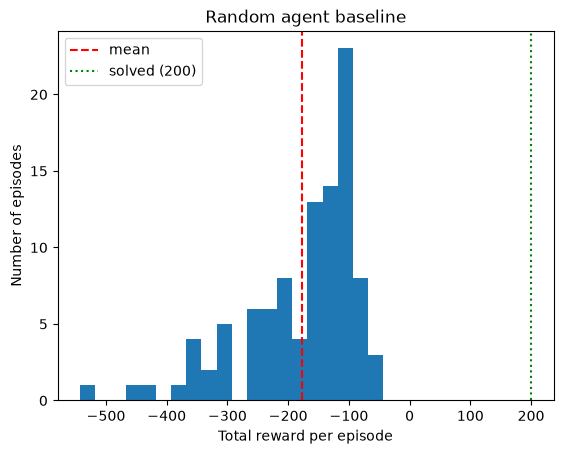

In [65]:
N_EVAL_EPISODES = 100

baseline_results = evaluate(env=env, agent=random_agent, n_episodes=N_EVAL_EPISODES)
baseline_summary = summarize_results(results=baseline_results)

print(f"Random agent over {N_EVAL_EPISODES} episodes")
print(f"Mean reward: {baseline_summary.mean_reward:.1f} ± {baseline_summary.std_reward:.1f}")
print(f"Mean steps:  {baseline_summary.mean_steps:.1f}")
print(f"End reasons: {baseline_summary.end_reasons}")

plot_reward_distribution(results=baseline_results, title="Random agent baseline")

### Baseline results

| Measure | Random agent |
|---|---|
| mean reward | −177.2 |
| standard deviation | 94.6 |
| median reward | −143.8 |
| best / worst episode | −43.4 / −542.5 |
| mean episode length | 93.9 steps (about 2 seconds) |
| end reasons | 95 crashes, 5 out of viewport, 0 at rest, 0 truncated |

* **No episode is positive.** The best one scores −43.4, and the mean is about 377 points below the threshold of 200: this is the gap PPO has to close.
* **The random agent almost always crashes, and quickly.** With no control, the lander falls nearly freely and hits the ground in about 2 seconds of simulation. It never lands (0 at rest) and never lasts until the time limit (0 truncated).
* **The distribution is asymmetric.** Half of the episodes (51) lie between −150 and −50, but a long tail goes down to −542.5 (14 episodes below −300), which pulls the mean below the median. The lowest scores come from episodes where random engine firings move the lander away from the pad or push it faster into the ground: these are penalized step after step, and the fuel spent costs points too.
* **The DQN notebook measured a close baseline** (−173.4 ± 110.0, 93 crashes and 7 out of viewport). The values differ slightly because its random agent uses another generator (`random.randrange`), but both describe the same behavior.

These results also give a first idea of what the learning curves should show: the agent must first stop crashing (more truncated episodes, while it learns to hover), then learn to land (at rest episodes appear, and the mean score goes above 0, then above 200).

## 4. Actor and critic

PPO learns with two neural networks that have different jobs:

| Network | Question it answers | Input | Output |
|---|---|---|---|
| **actor** | what should the lander do in this situation? | the observation (8 values) | one probability per action (4 values summing to 1): the **policy** |
| **critic** | how good is this situation? | the observation (8 values) | one value $V(s)$: the total reward the agent can still expect from this state by following its current policy |

During training, the action is **sampled** from the probabilities of the actor: an action with a probability of 0.85 is chosen most of the time, but not always. This is how PPO explores, with no epsilon-greedy. During evaluation, the agent stops exploring and always takes the most probable action.

The critic never chooses anything. It is a reference for the actor: after an action, comparing what really happened with what the critic expected tells whether the action was better or worse than usual (section 5). The actor then makes the good actions more likely and the bad ones less likely (section 6).

### Two separate networks

The subject allows one network with two outputs (two "heads" on a shared body) or two separate networks. This notebook uses **two separate networks**:

* **The two trainings do not interfere.** With a shared body, the loss of the actor and the loss of the critic update the same weights, and their coefficients must be balanced carefully so that one does not overwrite the other. With separate networks, each one only learns its own task.
* **It is the default of the reference implementations** for observations given as vectors (Stable-Baselines3, CleanRL).
* **The cost is negligible**: each network has a few thousand weights.

A shared body mostly pays off when the input is an image: the layers that "understand" the image are expensive, and sharing them saves a lot of computation. With 8 numbers as input, there is nothing worth sharing.

### Configuration

All the hyperparameters of PPO live in a single `PPOConfig`. It starts with the size of the networks only: each following section adds its own fields, with the reason behind each value.

`PPOConfig` is a frozen `dataclass` rather than a dictionary:

* **A typo is an immediate error.** `config.hiden_size` raises an `AttributeError`, while `CONFIG["hiden_size"]` is only noticed when the line runs.
* **Every field has a type and a default value**, so `PPOConfig()` is the reference configuration.
* **The configuration cannot change by accident during training**, since it is frozen. An experiment creates a modified copy instead: `replace(config, hidden_size=128)` changes one field and leaves the reference untouched. This is the method of section 9, where one hyperparameter changes at a time.

| Field | Value | Reason |
|---|---|---|
| `hidden_size` | 64 | number of neurons in each of the two hidden layers of the actor and of the critic. 64 is the standard size for PPO on small vector observations (Stable-Baselines3, CleanRL), and it is enough to map 8 inputs to 4 outputs. The DQN notebook uses 128, and section 9 can compare both sizes. |

In [66]:
@dataclass(frozen=True)
class PPOConfig:
    hidden_size: int = 64


config = PPOConfig()
print("Config:", config)


Config: PPOConfig(hidden_size=64)


### Building the networks

The actor and the critic share the same architecture: only the size of the output and one setting of the initialization differ. A single function, `build_mlp`, builds both.

```
                 ┌─ Linear(8, 64) ─ Tanh ─ Linear(64, 64) ─ Tanh ─ Linear(64, 4) ─► 4 logits   actor
observation (8) ─┤
                 └─ Linear(8, 64) ─ Tanh ─ Linear(64, 64) ─ Tanh ─ Linear(64, 1) ─► V(s)       critic
```

An MLP (multi-layer perceptron) is a sequence of `Linear` layers separated by activation functions. `build_mlp` returns an `nn.Sequential`: it is already a complete PyTorch module, whose forward pass runs the layers in order, so no custom class with a `forward` method is needed.

The layers between the input and the output are called **hidden layers**: their values stay inside the network and nobody reads them, unlike the input (the observation) and the output (the logits or $V(s)$). Each network here has two hidden layers of `hidden_size` = 64 neurons: the outputs of `Linear(8, 64)` and of `Linear(64, 64)`, each followed by `Tanh`. The last `Linear` is the **output layer**.

#### Tanh instead of ReLU

The DQN notebook uses `ReLU`. For PPO, `Tanh` is the standard choice (default of Stable-Baselines3 and CleanRL):

* `Tanh` squashes its outputs between −1 and 1, so the values inside the network stay bounded;
* the policy changes more smoothly from one update to the next, which is exactly what PPO tries to enforce;
* the large scale study of Andrychowicz et al. (2021, *What Matters in On-Policy Reinforcement Learning?*) found `Tanh` to work better than `ReLU` for PPO.

#### The actor outputs logits

The 4 outputs of the actor are **logits**: unbounded numbers, one per action, where a larger logit means a more likely action. The network has no `Softmax` at the end. In the next step, `Categorical(logits=...)` turns them into probabilities and computes the log probabilities in a numerically stable way. Computing `log(softmax(x))` in two separate steps can produce `log(0) = -inf` when a probability becomes tiny.

#### Orthogonal initialization

When a `Linear` layer is created, PyTorch already fills its weights and biases with random values (a uniform distribution whose range only depends on the number of inputs). These defaults are generic: they do not know that the network is a policy trained with PPO. The reference implementations replace them with an **orthogonal** initialization and a **gain** (a scale factor) chosen for each layer, for three reasons:

* **The actor must start with no preference.** At the start, the agent knows nothing, so it should try the 4 actions equally. With the default weights, the initial logits are not close to 0, and the actor can prefer one action in every state only because of the random draw. In one test draw, the default actor gave the probabilities 25.6%, 28.8%, 21.8% and 23.8% to the first observation, and the second action was the most likely in every tested state. With an output gain of 0.01, the logits are almost 0 and every probability is about 25%.
* **The signal must not fade from one layer to the next.** Each layer multiplies its inputs by its weights. If the weights are too small, the values shrink at every layer, and the last layers receive almost nothing to learn from. In a test with 10 `Tanh` layers of 64 neurons, the spread (standard deviation) of the values dropped from 0.46 to 0.09 with the default weights, and stayed around 0.56 with orthogonal weights and a gain of $\sqrt{2}$. An orthogonal matrix preserves the length of the vectors it multiplies, and the gain compensates for the squashing of `Tanh`. With two hidden layers only, the effect is smaller here, but the principle is the same.
* **No neuron should start with a random offset.** The default biases are random too, so each neuron is pushed in an arbitrary direction before seeing any observation. With biases at 0, only the weights decide at the start, and training adjusts the biases where they are useful.

| Layers | Gain | Reason |
|---|---|---|
| hidden layers | $\sqrt{2}$ | keeps the scale of the signal roughly constant from one layer to the next |
| output of the **actor** | 0.01 | the initial logits are almost 0, so the initial policy is almost uniform (about 25% per action): the agent starts with no preference and explores as much as possible |
| output of the **critic** | 1 | initial values on a normal scale, so the first errors of the critic stay moderate |
| all biases | 0 | no initial offset |

The default initialization would still train: it is not a bug, only a worse start. The large scale study of Andrychowicz et al. (2021) found that a small last layer for the actor is one of the choices that matter most for PPO, and orthogonal initialization is one of *The 37 Implementation Details of Proximal Policy Optimization* (Huang et al., 2022).

The three gains are constants rather than fields of `PPOConfig`: they are standard implementation choices, not hyperparameters that this notebook tunes.

In [67]:
HIDDEN_GAIN = np.sqrt(2)
ACTOR_OUTPUT_GAIN = 0.01
CRITIC_OUTPUT_GAIN = 1.0


def initialize_layer(*, layer: nn.Linear, gain: float) -> None:
    nn.init.orthogonal_(layer.weight, gain=gain)
    nn.init.zeros_(layer.bias)


def build_mlp(*, input_size: int, hidden_size: int, output_size: int, output_gain: float) -> nn.Sequential:
    input_layer = nn.Linear(input_size, hidden_size)
    hidden_layer = nn.Linear(hidden_size, hidden_size)
    output_layer = nn.Linear(hidden_size, output_size)

    initialize_layer(layer=input_layer, gain=HIDDEN_GAIN)
    initialize_layer(layer=hidden_layer, gain=HIDDEN_GAIN)
    initialize_layer(layer=output_layer, gain=output_gain)

    return nn.Sequential(input_layer, nn.Tanh(), hidden_layer, nn.Tanh(), output_layer)

The two networks are built from the environment dimensions and the configuration, then checked:

* the number of weights: $8 \times 64 + 64 = 576$, then $64 \times 64 + 64 = 4160$, then $64 \times 4 + 4 = 260$ for the actor (4996 in total), and $64 \times 1 + 1 = 65$ for the last layer of the critic (4801 in total);
* the initial policy on the first observation, which should be close to uniform thanks to the small output gain of the actor;
* the output shapes for a single observation and for a batch of 32 observations: training processes many observations at once, so both cases must work.

In [68]:
TEST_BATCH_SIZE = 32

actor = build_mlp(
    input_size=state_dim,
    hidden_size=config.hidden_size,
    output_size=n_actions,
    output_gain=ACTOR_OUTPUT_GAIN,
)
critic = build_mlp(
    input_size=state_dim,
    hidden_size=config.hidden_size,
    output_size=1,
    output_gain=CRITIC_OUTPUT_GAIN,
)
print(actor)
print(critic)


def count_parameters(*, network: nn.Module) -> int:
    return sum(parameter.numel() for parameter in network.parameters())


print("Actor parameters:", count_parameters(network=actor))
print("Critic parameters:", count_parameters(network=critic))

state_tensor = torch.as_tensor(state, dtype=torch.float32)
batch = torch.zeros(TEST_BATCH_SIZE, state_dim)

with torch.no_grad():
    initial_policy = torch.softmax(actor(state_tensor), dim=-1)
    print("Initial policy:", initial_policy)
    print("Single state:", actor(state_tensor).shape, critic(state_tensor).shape)
    print("Batch:", actor(batch).shape, critic(batch).shape)

Sequential(
  (0): Linear(in_features=8, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=4, bias=True)
)
Sequential(
  (0): Linear(in_features=8, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=1, bias=True)
)
Actor parameters: 4996
Critic parameters: 4801
Initial policy: tensor([0.2500, 0.2500, 0.2504, 0.2496])
Single state: torch.Size([4]) torch.Size([1])
Batch: torch.Size([32, 4]) torch.Size([32, 1])


### Network checks

| Check | Result | Expected |
|---|---|---|
| parameters of the actor | 4996 | $576 + 4160 + 260 = 4996$ |
| parameters of the critic | 4801 | $576 + 4160 + 65 = 4801$ |
| initial policy | 0.2500, 0.2500, 0.2504, 0.2496 | about 0.25 per action |
| shapes for one observation | actor `[4]`, critic `[1]` | 4 logits, 1 value |
| shapes for a batch of 32 | actor `[32, 4]`, critic `[32, 1]` | one row per observation |

**The architecture is correct.** The printed modules follow the diagram above, and the parameter counts match the sizes of the layers exactly. A parameter is one adjustable number of the network (a weight or a bias): these few thousand numbers are everything the networks know, and training will only adjust them. A mistake in the size of a layer would change these totals.

**The initial policy is uniform.** The first observation of the episode (lander near the center, high above the pad, legs off the ground) gives 4 logits of about $10^{-3}$, because of the output gain of 0.01. The softmax of 4 almost equal numbers is almost 25% for each action, and the largest gap is 0.04%. The actor starts with no preference: during the first rollouts, it samples the 4 actions equally, which is the most exploring behavior possible. The probabilities only move away from 25% once the PPO update starts to favor the actions with a positive advantage.

**The critic knows nothing yet.** Its output on the same observation is about $-0.1$, a value on a normal scale but with no meaning: the critic is not trained. A trained critic would give a large positive value to a state that leads to a landing and a negative value to a state that leads to a crash.

**Batches work without any change.** Given 32 observations at once, the networks return one output row per observation. `nn.Linear` applies the same weights to every row of its input in a single matrix product, with no Python loop. Training relies on this: the critic evaluates every state of a rollout in one call, and the PPO update processes minibatches of observations.

The networks are ready but untrained. The next step uses them to choose actions: sampling an action from the probabilities of the actor, and keeping its log probability and the value of the critic for the update.

### Choosing an action

During training, at every step of the game, the agent needs three things from the two networks:

1. **an action**, sampled from the probabilities of the actor. Sampling instead of always taking the most probable action is how PPO explores;
2. **the log probability of that action**, stored as the "old" probability. The PPO update compares it with the probability given by the updated actor (section 6);
3. **the value $V(s)$ of the state**, given by the critic. It is needed to compute the advantages (section 5).

`sample_action` computes the three at once and returns them in an `ActionSample`, a frozen dataclass like `EpisodeResult`: `sample.log_prob` is clearer than the second element of a tuple.

| Step | What happens | Example on the first observation |
|---|---|---|
| `actor(states)` | the actor outputs 4 logits | about $10^{-3}$ each |
| `Categorical(logits=...)` | builds a distribution over the 4 actions, with the probabilities given by the softmax of the logits | about 25% each |
| `distribution.sample()` | draws one action from this distribution | for example 2 (main engine) |
| `distribution.log_prob(action)` | the logarithm of the probability of the drawn action | $\log(0.25) \approx -1.386$ |
| `critic(states).squeeze(-1)` | the value of the state, without the last dimension of size 1 | about $-0.1$ |

#### Why `Categorical`

`torch.distributions.Categorical` gathers everything PPO needs about a discrete policy: sampling, log probabilities, and later the entropy used as an exploration bonus. It works on a single observation as well as on a batch, with no Python loop. Building it from `logits` rather than from probabilities lets PyTorch compute the log probabilities in a numerically stable way.

#### Why the log probability

The PPO update measures how much the policy changed with the ratio $\frac{\pi_{new}(a \mid s)}{\pi_{old}(a \mid s)}$, computed as $\exp(\log \pi_{new} - \log \pi_{old})$. Subtracting logarithms stays precise even when a probability becomes tiny, while dividing two tiny probabilities loses precision.

#### Why `torch.no_grad`

While playing, the agent collects data and does not learn. The stored log probabilities and values are fixed references for the update: they must not change when the networks are updated. The `@torch.no_grad()` decorator tells PyTorch not to record the computations for gradients, which saves memory and time and guarantees that the stored tensors are plain constants.

#### Checks

* on the first observation: an action between 0 and 3, a log probability close to $\log(0.25)$, and the value of the previous checks;
* on a batch of 32 observations: three tensors of shape `[32]`, one entry per observation;
* on 10,000 draws from the same observation: each action is drawn about 2,500 times, so the sampling follows the probabilities of the actor.

In [69]:
@dataclass(frozen=True)
class ActionSample:
    action: torch.Tensor
    log_prob: torch.Tensor
    value: torch.Tensor


@torch.no_grad()
def sample_action(*, actor: nn.Module, critic: nn.Module, states: torch.Tensor) -> ActionSample:
    distribution = Categorical(logits=actor(states))
    action = distribution.sample()
    return ActionSample(
        action=action,
        log_prob=distribution.log_prob(action),
        value=critic(states).squeeze(-1),
    )

In [70]:
N_SAMPLING_CHECKS = 10_000

single_sample = sample_action(actor=actor, critic=critic, states=state_tensor)
print("Single state:", single_sample)

batch_sample = sample_action(actor=actor, critic=critic, states=batch)
print("Batch shapes:", batch_sample.action.shape, batch_sample.log_prob.shape, batch_sample.value.shape)

repeated_states = state_tensor.repeat(N_SAMPLING_CHECKS, 1)
repeated_sample = sample_action(actor=actor, critic=critic, states=repeated_states)
print("Action counts:", torch.bincount(repeated_sample.action, minlength=n_actions))

Single state: ActionSample(action=tensor(3), log_prob=tensor(-1.3881), value=tensor(-0.1026))
Batch shapes: torch.Size([32]) torch.Size([32]) torch.Size([32])
Action counts: tensor([2510, 2487, 2473, 2530])


### Sampling checks

| Check | Result | Expected |
|---|---|---|
| action on the first observation | 3 (right engine) | any action between 0 and 3 |
| its log probability | $-1.3881$ | $\log(0.2496) \approx -1.3881$ |
| value of the first observation | $-0.1026$ | the value of the network checks |
| shapes for a batch of 32 | `[32]`, `[32]`, `[32]` | one action, one log probability and one value per observation |
| counts over 10,000 draws | 2510, 2487, 2473, 2530 | about 2,500 per action |

**The log probability matches the drawn action.** The actor gives a probability of 0.2496 to action 3 (section 4), and $\log(0.2496) \approx -1.3881$: `log_prob` returns the log probability of the action that was actually drawn, not an average over the actions. This is the number the rollout will store as the old probability.

**The value is the one of the critic.** $-0.1026$ is the output of the critic on the same observation, without its last dimension: `squeeze(-1)` turns the shape `[1]` into a single number, and the shape `[32, 1]` of a batch into `[32]`, so the values line up with the actions and the log probabilities.

**The sampling follows the policy.** With a probability of about 0.25 per action, 10,000 draws give 2,500 per action on average, with a typical gap of $\sqrt{10000 \times 0.25 \times 0.75} \approx 43$. The largest gap here is 30 (action 3), so the counts are what a fair 4 sided die would give. The 10,000 draws run in a single call, on a batch made of 10,000 copies of the observation.

**The function is ready for the rollout.** At every step, the agent will call `sample_action` on the current observation, send the action to the environment, and store the log probability and the value. Since the networks are untrained, the actions are still random, like the random baseline: what changes is that these probabilities can now be learned.